# Assignment 11: The Concept of a Pipeline

Dataset: `Diamond_Price_Prediction.csv`, 53,940 diamonds, 10 columns.

The aim of this assignment is the end-to-end flow of a machine learning model:
**data → EDA → split → fit the pipeline → predict with the pipeline**. You will
first prepare the data by hand, so that you can _see_ what a log transformation
and scaling do to it, and then put the same steps inside a single scikit-learn
`Pipeline` that does the job properly.

The assignment has two parts.

- **Part A (Q1 to Q9), regression.** Predict `price` with a pipeline, after
  seeing by hand what each preprocessing step does.
- **Part B (Q10 to Q13), an imbalanced classification problem.** Only 3% of the
  diamonds have a Fair cut. Predict which ones, and handle the class imbalance
  inside the pipeline, without leaking information from the test set.

Work through the questions in order. For each question, write your code and
then write your conclusions in the markdown cell below it.

Keep `Diamond_Price_Prediction.csv` in the same folder as this notebook.

Each question comes with a skeleton. The steps are laid out in order, the
variable names are chosen for you, and the line that prints or shows the result
is already written. Wherever you see `...` you supply the expression, and the
comment beside it tells you what is wanted. Delete the hint once it works.

The cell below sets everything up and gives you a set of helper functions for
the repetitive plotting. Read them, then use them.


In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, average_precision_score,
                             ConfusionMatrixDisplay)
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.manifold import TSNE
from matplotlib.lines import Line2D

# Part B uses imbalanced-learn: pip install imbalanced-learn
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import EditedNearestNeighbours
from imblearn import FunctionSampler
from sklearn.model_selection import cross_val_predict, StratifiedKFold

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid')
# Every plot gets a legend; make the legend text larger than the default.
plt.rcParams.update({'legend.fontsize': 12, 'legend.title_fontsize': 12,
                     'legend.frameon': True, 'legend.markerscale': 2})
warnings.filterwarnings('ignore', category=FutureWarning)   # quieten seaborn/pandas version notices

# The long column names in the file are replaced by short ones.
RENAME = {
    'Carat(Weight of Daimond)': 'carat',
    'Cut(Quality)': 'cut',
    'Color': 'color',
    'Clarity': 'clarity',
    'Depth': 'depth',
    'Table': 'table',
    'Price(in US dollars)': 'price',
    'X(length)': 'x',
    'Y(width)': 'y',
    'Z(Depth)': 'z',
}
NUMERIC = ['carat', 'depth', 'table', 'x', 'y', 'z']     # numeric inputs in the file
CATEGORICAL = ['cut', 'color', 'clarity']
TARGET = 'price'


def load_diamonds(file_path='Diamond_Price_Prediction.csv'):
    """Read the file and give the columns short names."""
    return pd.read_csv(file_path).rename(columns=RENAME)


df = load_diamonds()
print('rows, columns:', df.shape)
df.head()

rows, columns: (53940, 10)


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [2]:
# ---------------------------------------------------------------------
# Helper functions. These are given to you so that you spend your time on
# the analysis rather than on repetitive plotting code. Use them freely.
# ---------------------------------------------------------------------

def grid_of_histograms(data, columns, title=None, bins=50, kde=True, ncols=4, height=3.2):
    """Histogram (optionally with a KDE curve) for each column, with the mean and median marked."""
    columns = list(columns)
    nrows = int(np.ceil(len(columns) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4.2, nrows * height))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, columns):
        values = data[col].dropna()
        sns.histplot(values, bins=bins, kde=kde, ax=ax, label='histogram')
        if kde:
            ax.lines[-1].set_label('KDE')
        ax.axvline(values.mean(), color='red', ls='--', lw=1.5, label='mean')
        ax.axvline(values.median(), color='green', ls=':', lw=2, label='median')
        ax.set_title(col, fontsize=11)
        ax.set_xlabel(col)
        ax.set_ylabel('number of stones')
    for ax in axes[len(columns):]:
        ax.set_visible(False)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper right', bbox_to_anchor=(1.0, 1.06), ncol=len(labels))
    if title:
        fig.suptitle(title, x=0.02, y=1.04, ha='left', fontsize=13)
    fig.tight_layout()
    plt.show()


BOX_LEGEND = [Line2D([], [], color='black', lw=1.5, label='median'),
              Line2D([], [], marker='^', color='white', markerfacecolor='red',
                     markeredgecolor='red', markersize=7, label='mean'),
              Line2D([], [], marker='d', color='white', markerfacecolor='grey',
                     markeredgecolor='grey', markersize=6, label='outlier (1.5 x IQR)')]
BOX_STYLE = dict(showmeans=True, medianprops={'color': 'black', 'lw': 1.5},
                 meanprops={'marker': '^', 'markerfacecolor': 'red', 'markeredgecolor': 'red'})


def grid_of_boxplots(data, columns, title=None, ncols=4, height=3.2):
    """An individual box plot for each column, each on its own scale."""
    columns = list(columns)
    nrows = int(np.ceil(len(columns) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 3.6, nrows * height))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, columns):
        sns.boxplot(y=data[col].dropna(), ax=ax, color='skyblue', **BOX_STYLE)
        ax.set_title(col, fontsize=11)
        ax.set_ylabel(col)
    for ax in axes[len(columns):]:
        ax.set_visible(False)
    fig.legend(handles=BOX_LEGEND, loc='upper right', bbox_to_anchor=(1.0, 1.06), ncol=3)
    if title:
        fig.suptitle(title, x=0.02, y=1.04, ha='left', fontsize=13)
    fig.tight_layout()
    plt.show()


def common_scale_boxplot(data, columns, title, figsize=(11, 4.8), ylabel='value'):
    """Every column as a box plot on one shared vertical scale."""
    plt.figure(figsize=figsize)
    sns.boxplot(data=data[list(columns)], **BOX_STYLE)
    plt.title(title, fontsize=13)
    plt.xlabel('column')
    plt.ylabel(ylabel)
    plt.legend(handles=BOX_LEGEND, loc='upper right')
    plt.tight_layout()
    plt.show()


def correlation_heatmap(data, columns, title, figsize=(8, 6.5)):
    """Heatmap of the pairwise correlation coefficients; returns the matrix."""
    corr = data[list(columns)].corr()
    plt.figure(figsize=figsize)
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
                cbar_kws={'label': 'Pearson correlation coefficient'})
    plt.title(title, fontsize=13)
    plt.tight_layout()
    plt.show()
    return corr


def count_plots(data, columns, height=3.8):
    """A frequency bar chart for each categorical column, bars labelled with their share."""
    columns = list(columns)
    fig, axes = plt.subplots(1, len(columns), figsize=(len(columns) * 4.8, height))
    for ax, col in zip(np.atleast_1d(axes), columns):
        order = data[col].value_counts().index
        sns.countplot(x=data[col], order=order, ax=ax, color='steelblue', label='number of stones')
        shares = (100 * data[col].value_counts(normalize=True)[order]).round(1)
        ax.bar_label(ax.containers[0], labels=[f'{v}%' for v in shares], fontsize=8)
        ax.set_title(col, fontsize=11)
        ax.set_xlabel(col)
        ax.set_ylabel('number of stones')
        ax.tick_params(axis='x', rotation=45)
        ax.legend(loc='upper right')
    fig.tight_layout()
    plt.show()


def regression_metrics(y_true, y_pred):
    """RMSE, MAE and R squared for one set of predictions."""
    return {'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'MAE': mean_absolute_error(y_true, y_pred),
            'R2': r2_score(y_true, y_pred)}


def diagnostic_plots(y_true, y_pred, label):
    """Actual vs predicted, residuals vs predicted, and a QQ plot of the residuals."""
    y_true = np.asarray(y_true)
    residuals = y_true - y_pred
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

    axes[0].scatter(y_true, y_pred, s=4, alpha=0.3, label='diamonds')
    lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    axes[0].plot(lims, lims, 'r--', lw=1.5, label='perfect prediction')
    axes[0].set_xlabel('Actual price (USD)')
    axes[0].set_ylabel('Predicted price (USD)')
    axes[0].set_title(f'{label}: actual vs predicted')
    axes[0].legend()

    axes[1].scatter(y_pred, residuals, s=4, alpha=0.3, label='diamonds')
    axes[1].axhline(0, color='r', ls='--', lw=1.5, label='zero residual')
    axes[1].set_xlabel('Predicted price (USD)')
    axes[1].set_ylabel('Residual = actual - predicted (USD)')
    axes[1].set_title(f'{label}: residuals vs predicted')
    axes[1].legend()

    stats.probplot(residuals, dist='norm', plot=axes[2])
    axes[2].get_lines()[0].set_label('residual quantiles')
    axes[2].get_lines()[1].set_label('normal reference line')
    axes[2].set_title(f'{label}: QQ plot of residuals')
    axes[2].set_xlabel('Theoretical normal quantiles')
    axes[2].set_ylabel('Ordered residuals (USD)')
    axes[2].legend()

    fig.tight_layout()
    plt.show()


def classification_metrics(y_true, y_pred, y_score=None):
    """Metrics for a binary problem whose positive class (1) is the rare one."""
    out = {'accuracy': accuracy_score(y_true, y_pred),
           'balanced accuracy': balanced_accuracy_score(y_true, y_pred),
           'precision': precision_score(y_true, y_pred, zero_division=0),
           'recall': recall_score(y_true, y_pred),
           'F1': f1_score(y_true, y_pred)}
    if y_score is not None:
        out['average precision (PR-AUC)'] = average_precision_score(y_true, y_score)
    return out


def confusion_matrices(models, X, y, labels=('not Fair', 'Fair')):
    """Draw a confusion matrix for each fitted model in a {name: model} dict."""
    fig, axes = plt.subplots(1, len(models), figsize=(5.6 * len(models), 4.4))
    for ax, (name, model) in zip(np.atleast_1d(axes), models.items()):
        ConfusionMatrixDisplay.from_estimator(model, X, y, display_labels=labels,
                                              ax=ax, colorbar=True, cmap='Blues',
                                              values_format='d')
        ax.images[-1].colorbar.set_label('number of test stones')
        ax.set_title(name, fontsize=11)
        ax.grid(False)
    fig.tight_layout()
    plt.show()

# Part A: predicting the price


## Q1. Data understanding and integrity checks

Carry out the following checks on the raw data, before changing anything.

a. How many rows and columns are there? How many missing values?

b. How many exact duplicate rows are there? Decide whether to remove them, and
justify the decision. Say what a duplicate would mean for a diamond listing
specifically, not just in general.

c. The columns `x`, `y` and `z` are the length, width and depth of the stone in
millimetres. How many rows have a zero in one of them? Why is a zero impossible,
and why is it better to treat it as missing than to keep it as a number?

d. Zeros are not the only impossible values. Look at the largest values of `y`
and `z` and compare each with the carat weight of the same stone. What do you
find, and would the 1.5 × IQR rule be the right tool for catching it?


In [13]:
# Q1 a. Size and missing values
shape = df.shape                 
n_missing =df.isnull().sum().sum()
print('rows and columns:', shape)
print('missing values:', n_missing)


# Q1 b. Exact duplicate rows
n_duplicates = df.duplicated().sum()
print()
print('exact duplicate rows: %s (%.2f%%)' % (n_duplicates, 100 * n_duplicates / len(df)))
# Look at a few of them before deciding.
print(df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(6))


# Q1 c. Zero dimensions
zero_counts = (df[['x', 'y', 'z']] == 0).sum()
rows_with_a_zero = (df[['x', 'y', 'z']] == 0).any(axis=1).sum()
print()
print('zeros in each dimension:')
print(zero_counts.to_string())
print('rows with at least one zero dimension:', rows_with_a_zero)
print(df[(df[['x', 'y', 'z']] == 0).any(axis=1)].head())


# Q1 d. The largest dimensions, next to the weight of the same stone
print()
print('largest y:')
print(df.nlargest(4, 'y')[['carat', 'x', 'y', 'z', 'price']])                      
print()
print('largest z:')
print(df.nlargest(4, 'z')[['carat', 'x', 'y', 'z', 'price']])                      
# A typical 0.5 carat stone is about 5 mm across. Is a 32 mm stone of that
# weight possible?

rows and columns: (53940, 10)
missing values: 0

exact duplicate rows: 146 (0.27%)
       carat    cut color clarity  depth  table  price     x     y     z
43995    0.3   Good     J     VS1   63.4   57.0    394  4.23  4.26  2.69
47296    0.3   Good     J     VS1   63.4   57.0    394  4.23  4.26  2.69
34408    0.3  Ideal     G      IF   62.1   55.0    863  4.32  4.35  2.69
34422    0.3  Ideal     G      IF   62.1   55.0    863  4.32  4.35  2.69
28592    0.3  Ideal     G     VS2   63.0   55.0    675  4.31  4.29  2.71
28593    0.3  Ideal     G     VS2   63.0   55.0    675  4.31  4.29  2.71

zeros in each dimension:
x     8
y     7
z    20
rows with at least one zero dimension: 20
       carat      cut color clarity  depth  table  price     x     y    z
2207    1.00  Premium     G     SI2   59.1   59.0   3142  6.55  6.48  0.0
2314    1.01  Premium     H      I1   58.1   59.0   3167  6.66  6.60  0.0
4791    1.10  Premium     G     SI2   63.0   59.0   3696  6.50  6.47  0.0
5471    1.01  Prem

**Your conclusions for Q1:**

a.
Rows: 53940
Columns: 10
Missing values: 0

b.
Duplicates: 146 rows
I would think of removing them because it is difficut to imagine 2 diamonds with same dimensions, clarity, color, cut, carat and price. Diamonds occur naturally but they are later cut and polished, it is not always you will recieve exact diamonds.

c.
A diamond is a 3-dimensional object hence the value of x, y and z can't be 0. It is most likely a missing value if a 0 is seen.

d.
Very large values for x, y and z would be suspicious especially if it happens for diamonds with low carats. We can't have a huge diamond with less weight. The 1.5 X IQR formula would help us find the outliers but the corelation between the diamond weight(carat) and possible values is necessary.


## Q2. Distributions

a. Draw a histogram with a KDE curve and a box plot for every numeric column,
including the target `price`. Which columns are strongly skewed, which are close
to symmetric? Back what you say with the skewness of each column.

b. Draw a frequency plot for each of the three categorical columns `cut`,
`color` and `clarity`. Which classes are rare?

c. Draw all the numeric input columns (not `price`) as box plots on one common
scale. What do you see, and what does it mean for a model that measures
distances or assigns weights to features?


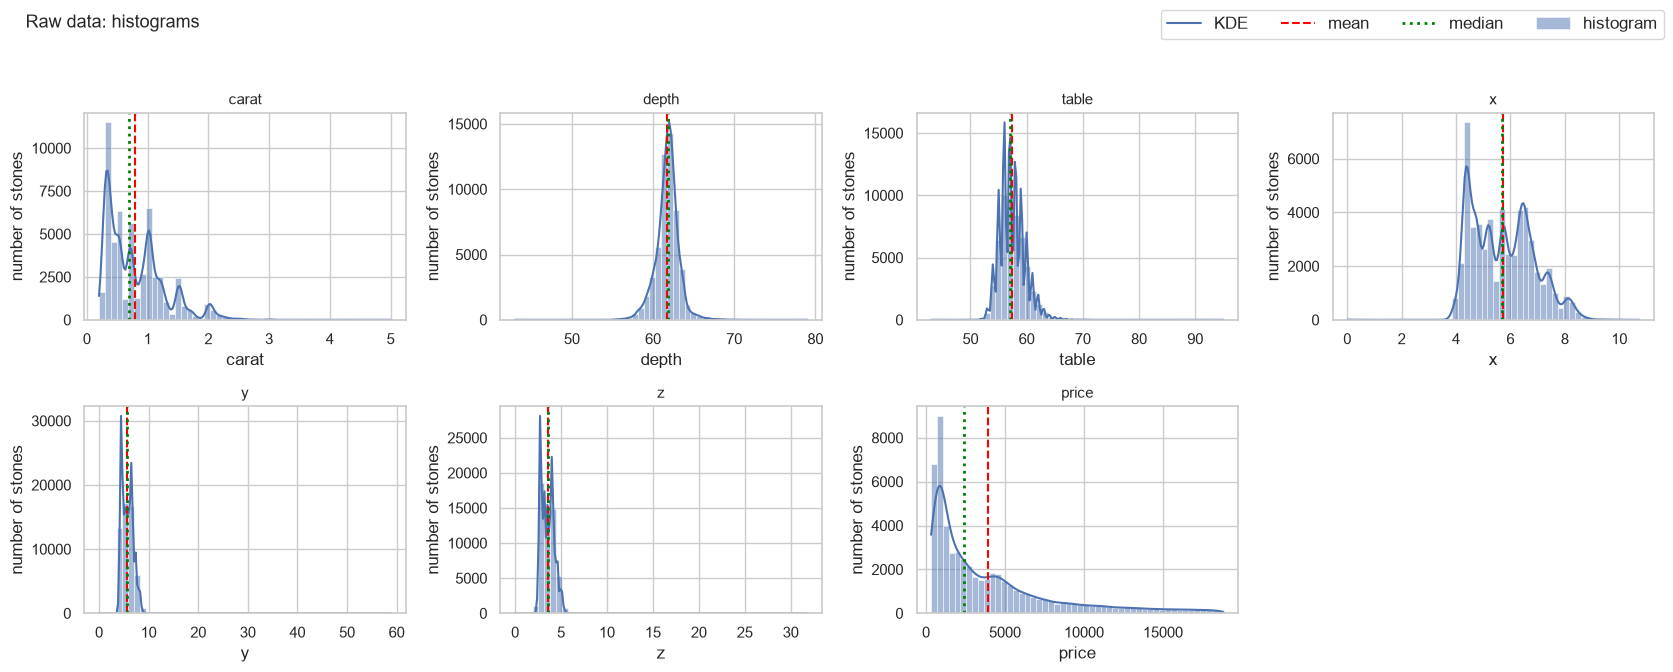

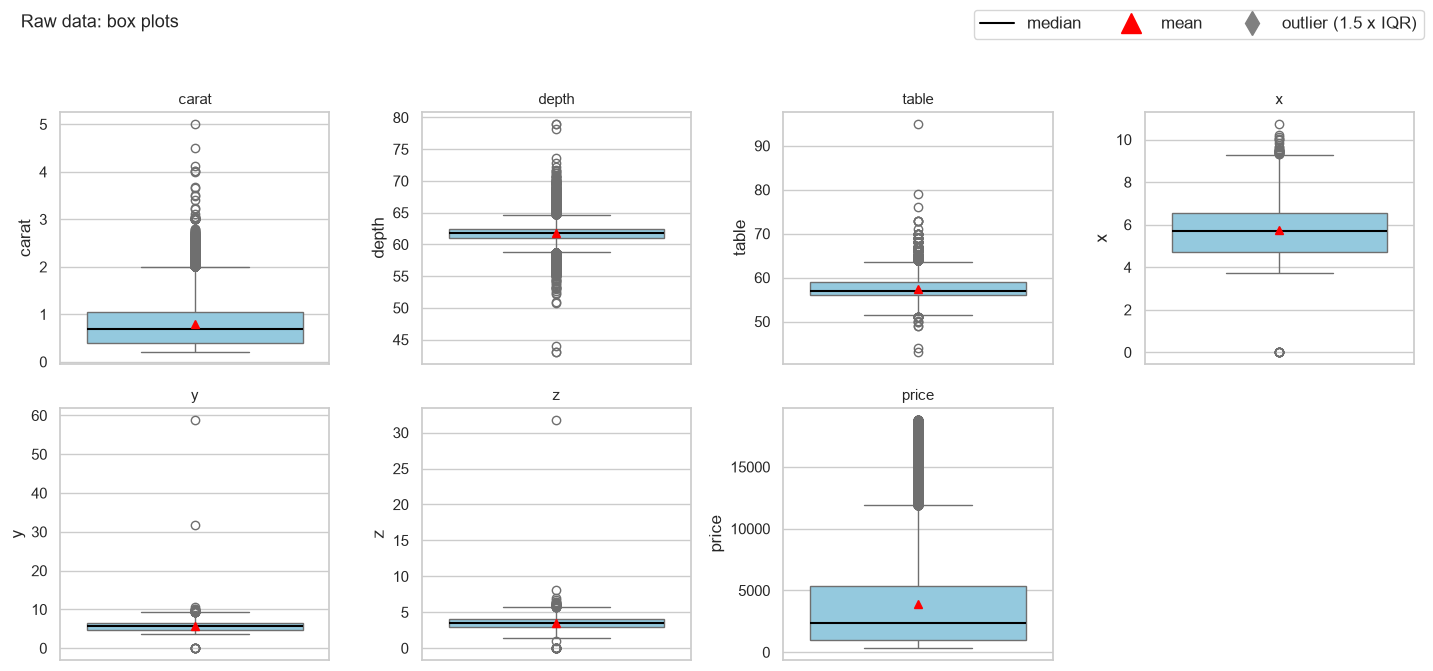

skewness of each column:
y        2.43
price    1.62
z        1.52
carat    1.12
table    0.80
x        0.38
depth   -0.08


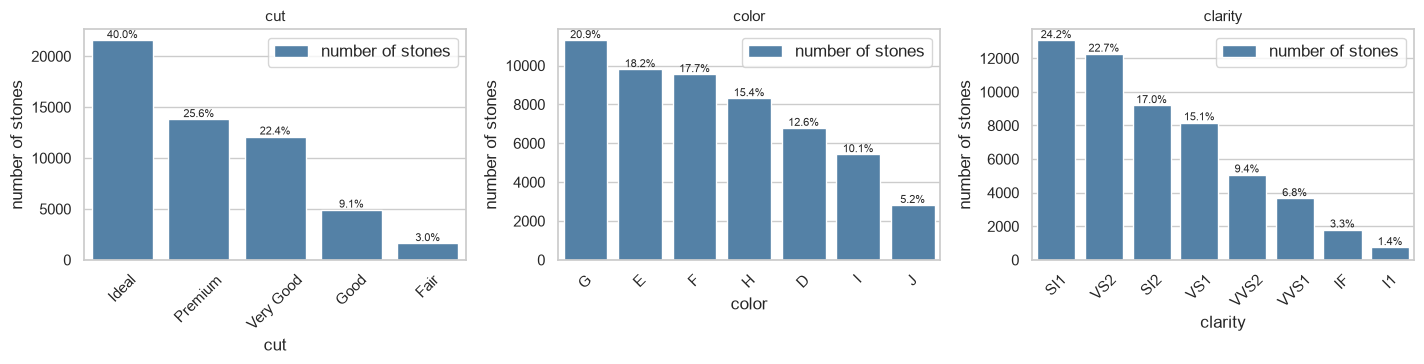

--- cut ---
cut
Ideal        21551
Premium      13791
Very Good    12082
Good          4906
Fair          1610
--- color ---
color
G    11292
E     9797
F     9542
H     8304
D     6775
I     5422
J     2808
--- clarity ---
clarity
SI1     13065
VS2     12258
SI2      9194
VS1      8171
VVS2     5066
VVS1     3655
IF       1790
I1        741


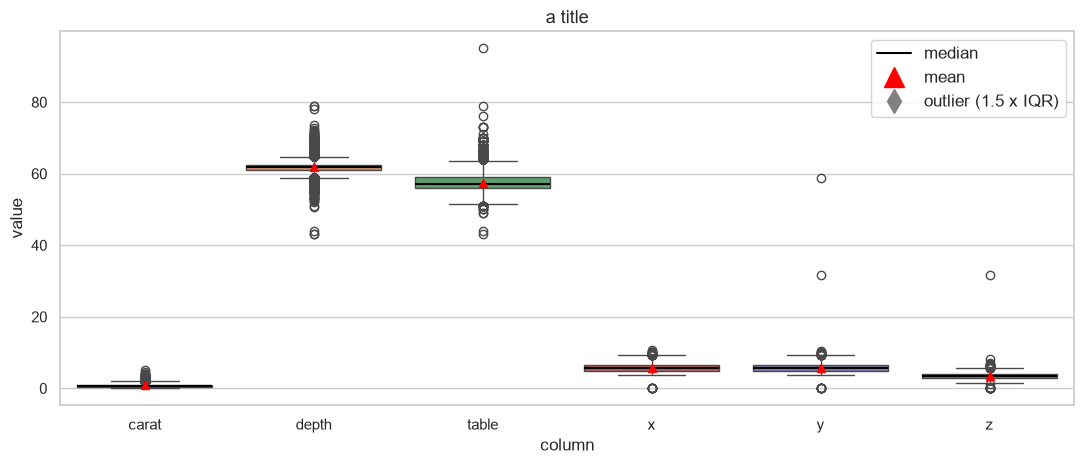

        min    max   mean   std
carat   0.2   5.01   0.80  0.47
depth  43.0  79.00  61.75  1.43
table  43.0  95.00  57.46  2.23
x       0.0  10.74   5.73  1.12
y       0.0  58.90   5.73  1.14
z       0.0  31.80   3.54  0.71


In [14]:
# Q2 a. Histograms and box plots for every numeric column
numeric_with_target = NUMERIC + [TARGET]
grid_of_histograms(df, numeric_with_target, title='Raw data: histograms')
grid_of_boxplots(df, numeric_with_target, title='Raw data: box plots')

skewness = df[numeric_with_target].skew().round(2)
print('skewness of each column:')
print(skewness.sort_values(ascending=False).to_string())


# Q2 b. The categorical columns
count_plots(df, CATEGORICAL)
for col in CATEGORICAL:
    print('--- %s ---' % col)
    print(df[col].value_counts().to_string())


# Q2 c. All numeric inputs on one common scale
common_scale_boxplot(df, NUMERIC, 'a title')
print(df[NUMERIC].agg(['min', 'max', 'mean', 'std']).T.round(2))
# The skewness of y and z is far higher than that of x. Q1 d explains why.

**Your conclusions for Q2:**

a.
| Column | Type | Skewness | Observation |
| ------ | ---------------------------------------------- | -------- | -------------------------------------------------------------------------------------------------- |
| Carat | Right-skewed | 1.12 | Most diamonds have lower carat weights, with some having high weights |
| Depth | Approximately symmetric | -0.08 | Values are concentrated around 61–62, with the mean and median close together. |
| Table | Approximately symmetric | 0.8 | Most values are concentrated around 56–59, with a small right tail. |
| x | Approximately symmetric, slightly right skewed | 0.38 | Values are spread across multiple peaks, with some larger values forming a right tail. |
| y | Right-skewed | 2.43 | Most values are concentrated around 5–7, but extremely large values extend the right tail. |
| z | Right-skewed | 1.52 | Most values are concentrated around 2–4, with a few unusually large values. |
| price | Right-skewed | 1.62 | Most diamonds are relatively inexpensive, while a smaller number have substantially higher prices. |

b.
Rare classes in each column:
Cut: Fair
Color: J
Clarity: I1

c.
The box plot shows that some of the columns have very high numerical values compared to others. Which is seen with the depth and table column. There are quite a few outliers in the columns. Especially y and z columns having singular outliers which are very far away from the IQR.
For a model which measures distances or assigns weights it would mislead the model because the large values would overshadow the significance of other columns.


## Q3. Relationships, and a new feature

a. Create a feature `volume = x * y * z`, with the zero dimensions treated as
missing (Q1 c). Then draw a heatmap of the correlations between all the numeric
columns, `volume` and `price` included.

b. Which features are most strongly related to `price`? Which pairs of features
are telling you the same thing twice? What does `volume` add, if anything, over
`carat`?


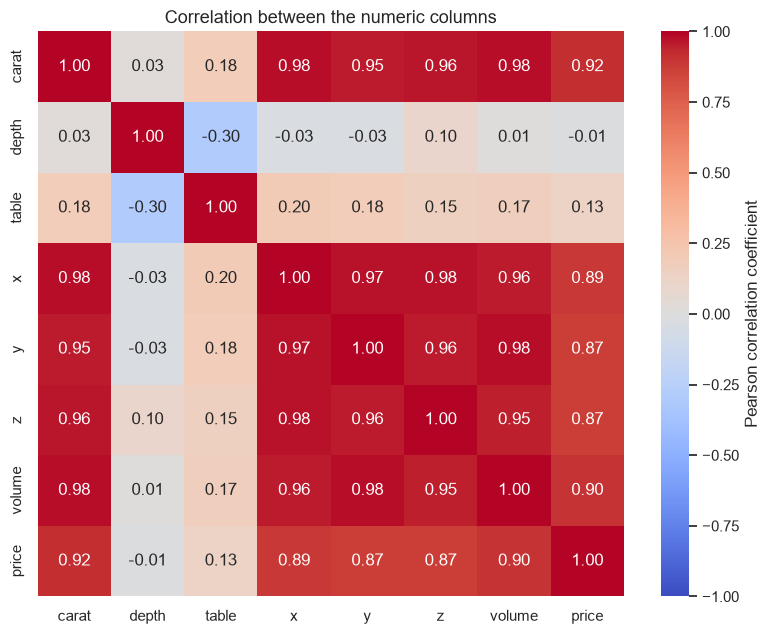

correlation with price, strongest first:
carat     0.921591
volume    0.904255
x         0.887227
z         0.868206
y         0.867870
table     0.127134
depth    -0.010647
Name: price, dtype: float64

volume per carat: median 163.5, max 1920.3


In [17]:
# Q3 a. Build volume, with impossible zero dimensions treated as missing
with_volume = df.copy()
with_volume[['x', 'y', 'z']] = with_volume[['x', 'y', 'z']].replace(0, np.nan)   
with_volume['volume'] = with_volume['x'] * with_volume['y'] * with_volume['z']

corr = correlation_heatmap(with_volume, NUMERIC + ['volume', TARGET],
                           'Correlation between the numeric columns')

print('correlation with price, strongest first:')
print(corr[TARGET].drop(TARGET).sort_values(ascending=False))


# Q3 b. A volume of a few hundred cubic millimetres per carat is normal. The
# typos from Q1 d show up here too.
ratio = with_volume['volume'] / with_volume['carat']
print()
print('volume per carat: median %.1f, max %.1f' % (ratio.median(), ratio.max()))

**Your conclusions for Q3:**

b.
Carat is most strongly related to price followed by volume and then the columns x, y and z which are responsible for the volume column.

\[ Carat, Volume, x, y, z ], a pair of these columns seem to be highly co-related.
Volume might help us to relate Carat with the x, y and z dimensions of a diamond. Carat of 2 diamonds might be same but volume might be different by a small factor which could be helpful.


## Q4. Preparing the data by hand, to see what the steps do

Before building the pipeline, carry out its steps by hand on the training data,
so that you can see what each one does. This part is for understanding only; the
model in Q6 does not use any of it.

a. Starting from a copy of the raw data: replace the zero dimensions with `NaN`,
create `volume`, and drop `cut`, `color` and `clarity` (no encoding is used in
this assignment).

b. Split into training and test sets (`test_size=0.2`, `random_state=42`)
**before** transforming anything.

c. Apply `np.log1p` to the numeric input columns only, never to `price`. Draw the
histograms of the training inputs after the log and compare the skewness before
and after. Which columns did the log help, and which did it barely change?

d. Standardise the log-transformed inputs with a `StandardScaler` fitted on the
training rows only, and apply the same scaler to the test rows. Draw the common
scale box plot again. What did scaling change, and what did it leave exactly as
it was?


columns kept: ['carat', 'depth', 'table', 'price', 'x', 'y', 'z', 'volume']
train rows: 43152, test rows: 10788


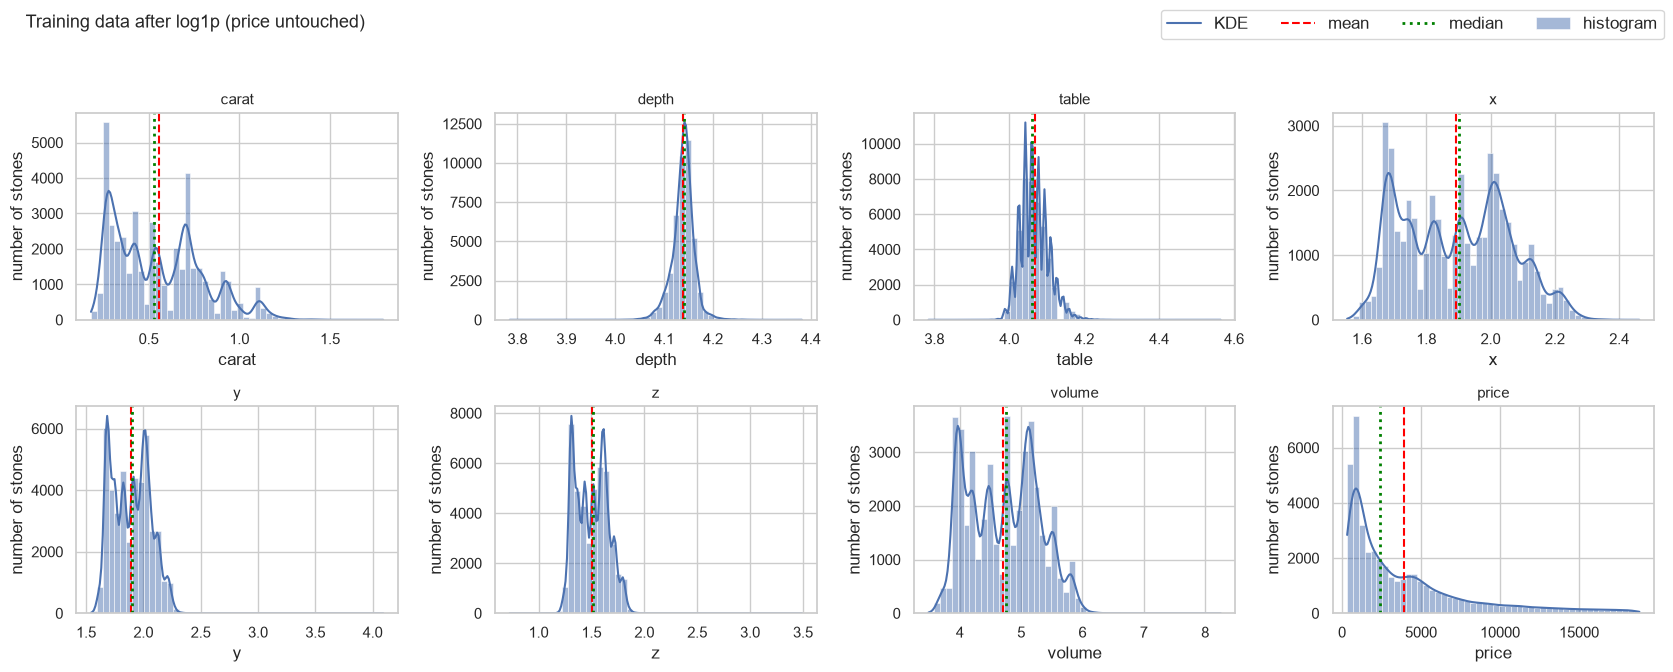

        skew before log  skew after log
carat              1.11            0.58
depth             -0.09           -0.34
table              0.81            0.60
x                  0.40            0.14
y                  2.94            0.22
z                  1.87            0.21
volume             3.49            0.11


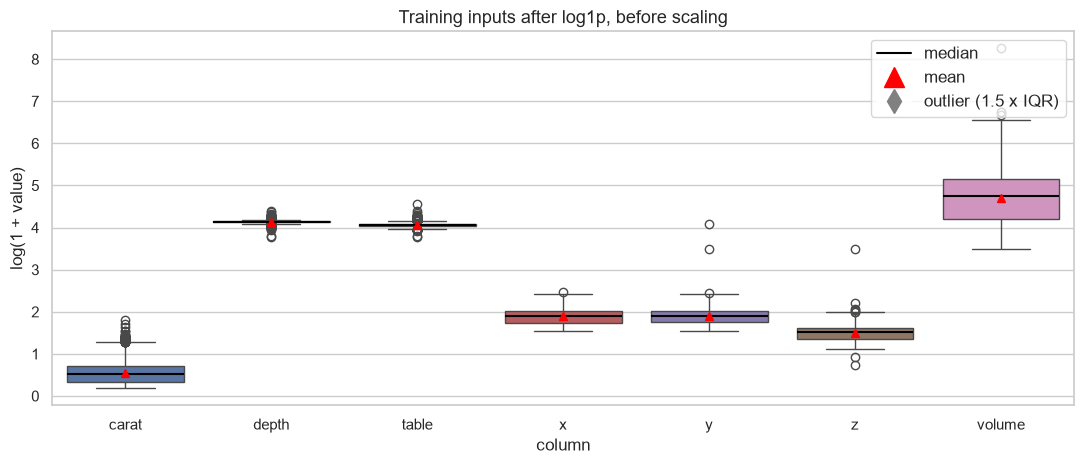

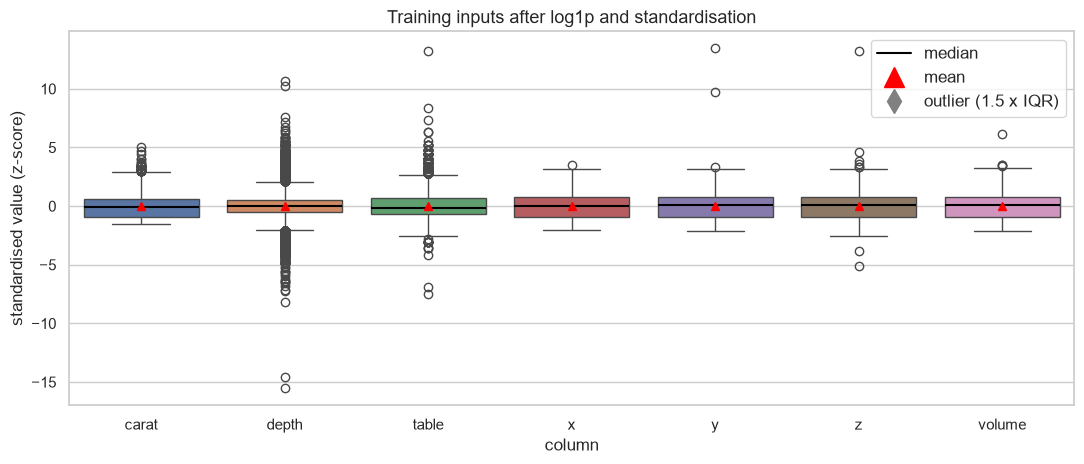

        mean  std
carat   -0.0  1.0
depth   -0.0  1.0
table   -0.0  1.0
x       -0.0  1.0
y        0.0  1.0
z       -0.0  1.0
volume  -0.0  1.0

largest change in skewness caused by scaling: 3.02e-14


In [18]:
# Q4 a. Clean and build features on a copy of the raw data
manual = df.copy()
manual[['x', 'y', 'z']] = manual[['x', 'y', 'z']].replace(0, np.nan)
manual['volume'] =manual['x'] * manual['y'] * manual['z']
manual = manual.drop(columns=CATEGORICAL)
features = NUMERIC + ['volume']
print('columns kept:', list(manual.columns))


# Q4 b. Split FIRST
train_df, test_df = train_test_split(manual, test_size=0.2, random_state=42)
train_df, test_df = train_df.copy(), test_df.copy()
print('train rows: %d, test rows: %d' % (len(train_df), len(test_df)))


# Q4 c. Log transform the inputs only. log1p has nothing to learn, so it can
# be applied to both sets directly.
skew_before = train_df[features].skew()
train_df[features] = np.log1p(train_df[features])
test_df[features] = np.log1p(test_df[features])
skew_after = train_df[features].skew()

grid_of_histograms(train_df, features + [TARGET], title='Training data after log1p (price untouched)')
print(pd.DataFrame({'skew before log': skew_before, 'skew after log': skew_after}).round(2).to_string())


# Q4 d. Standardise: fit on the training rows only, then reuse on the test rows
def apply_standardization(train_df, test_df, columns):
    scaler = StandardScaler()
    train_df[columns] = scaler.fit_transform(train_df[columns])
    test_df[columns] =  scaler.transform(test_df[columns])
    return train_df, test_df, scaler


common_scale_boxplot(train_df, features, 'Training inputs after log1p, before scaling',
                     ylabel='log(1 + value)')
skew_before_scaling = train_df[features].skew()
train_df, test_df, scaler = apply_standardization(train_df, test_df, features)
common_scale_boxplot(train_df, features, 'Training inputs after log1p and standardisation',
                     ylabel='standardised value (z-score)')

print(train_df[features].agg(['mean', 'std']).T.round(3).to_string())
print()
print('largest change in skewness caused by scaling: %.2e'
      % (train_df[features].skew() - skew_before_scaling).abs().max())
# Is that number what you expected? Explain it.

**Your conclusions for Q4:**

c.
It helped the Carat, x, y, z and Volume columns the most.

d.
Scaling changes the magnitude of the values of columns. It does not cause a change in the shape (skewness) of data.


## Q5. Why the order matters

In Q4 you split first and fitted the scaler on the training rows only.

a. Fit a second scaler on **all** the rows instead, and compare the means and
standard deviations it learns with those learned from the training rows. How
large is the difference here?

b. The difference is small for this file. Explain why fitting on all the rows is
still wrong, what the test score would then be measuring, and in what kind of
dataset the same mistake would do real damage.


In [19]:
# Q5 a. A scaler fitted on every row, for comparison only
all_rows = np.log1p(manual[features])
leaky_scaler = StandardScaler().fit(all_rows)

compare = pd.DataFrame({
    'mean (train only)': scaler.mean_,
    'mean (all rows)': leaky_scaler.mean_,
    'std (train only)': scaler.scale_,
    'std (all rows)': leaky_scaler.scale_
}, index=features)
compare['mean difference (in train std)'] = (compare['mean (all rows)']
                                             - compare['mean (train only)']) / compare['std (train only)']
print(compare.round(4).to_string())
# Small numbers here do not make the method right. Say why in markdown.

        mean (train only)  mean (all rows)  std (train only)  std (all rows)  mean difference (in train std)
carat              0.5556           0.5553            0.2445          0.2449                         -0.0010
depth              4.1388           4.1389            0.0228          0.0229                          0.0044
table              4.0676           4.0676            0.0377          0.0378                         -0.0012
x                  1.8935           1.8933            0.1643          0.1645                         -0.0017
y                  1.8941           1.8938            0.1636          0.1638                         -0.0019
z                  1.5016           1.5014            0.1508          0.1510                         -0.0012
volume             4.7117           4.7108            0.5725          0.5734                         -0.0016


**Your conclusions for Q5:**

a.
If we compare the differences it is very small.

b.
Although the differences are very small, fitting the scaler on all rows is still incorrect because it introduces data leakage. The scaler uses information from the test set to calculate its mean and standard deviation. Consequently, the test data is no longer completely unseen during preprocessing, making the evaluation less independent.


## Q6. Build and run the pipeline

Now start again from the **raw** data, so that nothing from Q4 leaks in, and do
it properly.

a. Write `feature_engineer_numeric_only(X)`. It takes the raw input columns,
replaces the zero dimensions with `NaN`, creates `volume`, drops the categorical
columns, and returns only `carat`, `depth`, `table`, `x`, `y`, `z` and `volume`.

b. Write `run_pipeline_log(df)`. It separates `X` and `y`, splits them
(`test_size=0.2`, `random_state=42`), and builds an `SkPipeline` with these
steps, in this order:

1. `FunctionTransformer(feature_engineer_numeric_only)`
2. `SimpleImputer(strategy='median')`
3. `FunctionTransformer(np.log1p)`
4. `StandardScaler()`
5. `RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)`

Fit it with `pipeline.fit(X_train, y_train)` only, predict on both sets with
`pipeline.predict`, and return the fitted pipeline with the split data.

c. Report RMSE, MAE and R² on the training and the test set, and compare both
with simply predicting the mean training price every time.


In [22]:
# Q6 a. Feature engineering, written to run inside the pipeline
def feature_engineer_numeric_only(X):
    X = pd.DataFrame(X).copy()
    X[['x', 'y', 'z']] = X[['x', 'y', 'z']].replace(0, np.nan)
    X['volume'] = X['x'] * X['y'] * X['z']
    X = X.drop(columns=CATEGORICAL, errors='ignore')
    return X[['carat', 'depth', 'table', 'x', 'y', 'z', 'volume']]


# Q6 b. The whole flow in one function
def run_pipeline_log(df):
    data = df.copy()
    X = data.drop(columns=[TARGET])
    y = data[TARGET]
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42
    )

    pipeline = SkPipeline([
        ('features', FunctionTransformer(feature_engineer_numeric_only)),
        ('impute', SimpleImputer(strategy='median')),
        ('log',  FunctionTransformer(np.log1p)),
        ('scale',StandardScaler()),
        ('model', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)),
    ])
    pipeline.fit(X_train, y_train)
    return pipeline, X_train, X_test, y_train, y_test


raw = load_diamonds()                   # start again from the raw file
pipeline, X_train, X_test, y_train, y_test = run_pipeline_log(raw)
pred_train = pipeline.predict(X_train)
pred_test = pipeline.predict(X_test)


# Q6 c. Metrics, against the laziest possible model
baseline = np.full(len(y_test), y_train.mean())
results = pd.DataFrame({
    'train': regression_metrics(y_train, pred_train),
    'test': regression_metrics(y_test, pred_test),
    'predict the mean (test)': regression_metrics(y_test, baseline),
}).T.round(3)
print(results.to_string())

                             RMSE       MAE     R2
train                     520.149   293.568  0.983
test                     1363.692   774.879  0.883
predict the mean (test)  3987.222  3020.506 -0.000


**Your conclusions for Q6:**

The train and test values have less errors than simply predicting the mean. The errors are significantly more on test, which suggests overfitting.


## Q7. Diagnostic plots

Draw the three diagnostic plots (actual vs predicted, residuals vs predicted, and
a QQ plot of the residuals) for the training set and for the test set.

a. Compare the training and the test results, both the plots and the metrics
from Q6. What does the gap between them tell you about the random forest?

b. Do the residuals have the same spread at every price? What does the QQ plot
say about whether they are normally distributed, and does that matter for this
model?


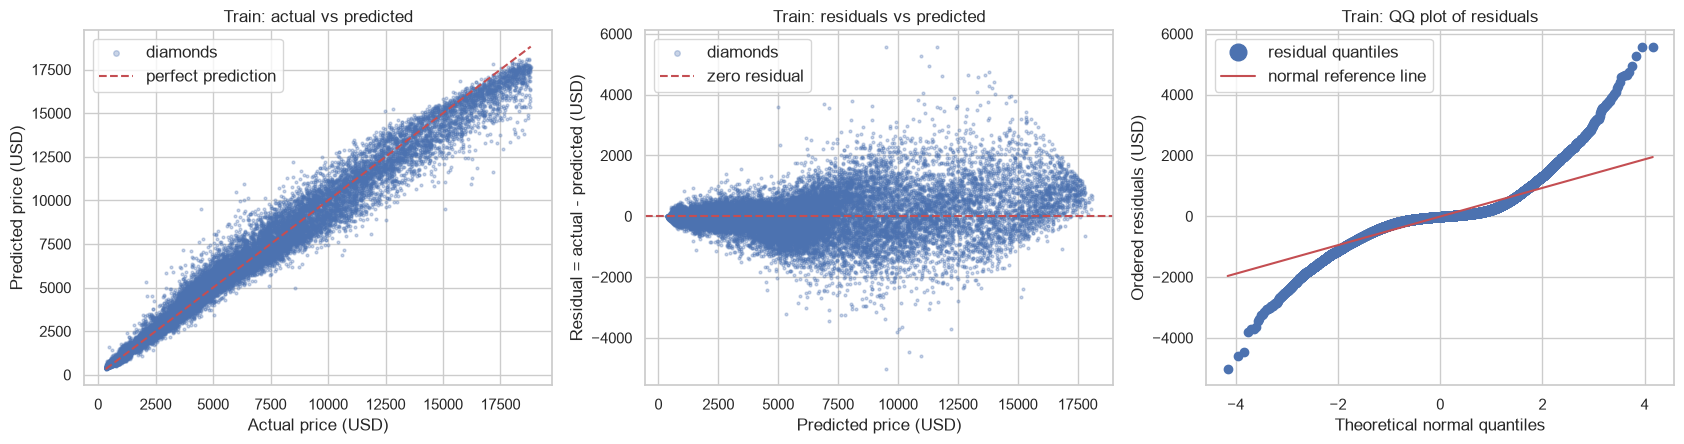

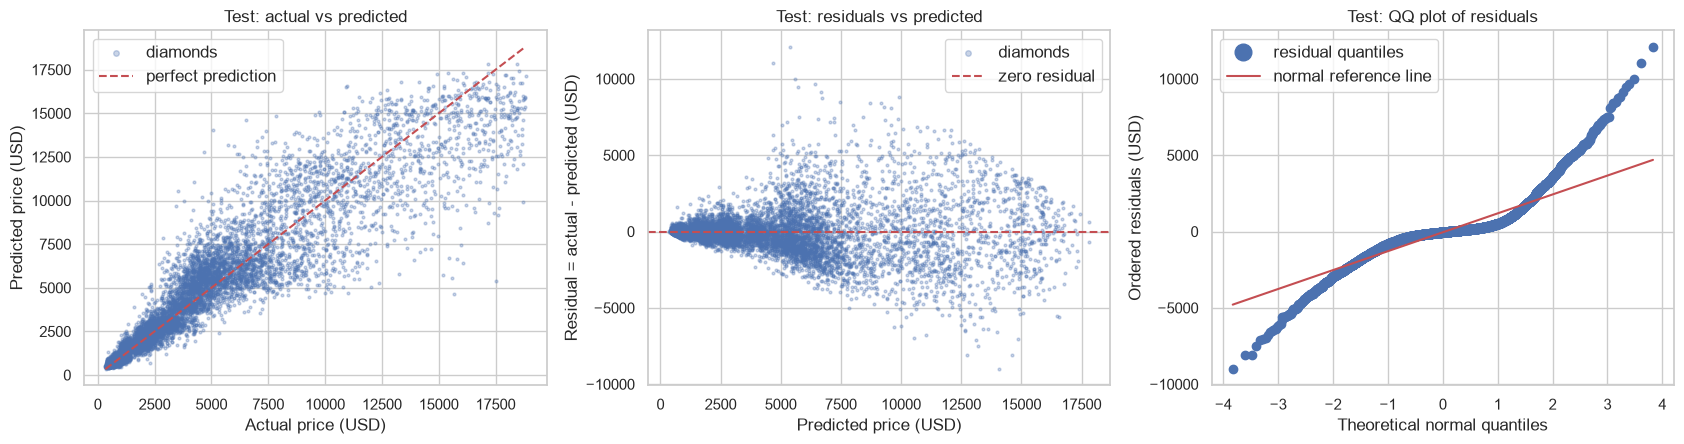

spread of the test residuals by predicted price:
               mean     std
cheapest 25%    9.4   166.6
second 25%     -5.1   384.5
third 25%      19.9  1157.9
dearest 25%  -212.1  2424.8


In [23]:
# Q7. Diagnostics for both sets
diagnostic_plots(y_train, pred_train, 'Train')
diagnostic_plots(y_test, pred_test, 'Test')

# Put a number on whether the errors grow with the price.
residuals =  y_test - pred_test
bands = pd.qcut(pred_test, 4, labels=['cheapest 25%', 'second 25%', 'third 25%', 'dearest 25%'])
print('spread of the test residuals by predicted price:')
print(residuals.groupby(bands, observed=True).agg(['mean', 'std']).round(1).to_string())

**Your conclusions for Q7:**

a.
Considering above and Q6 metrics, we have
Training performance is strong (RMSE = 520, MAE = 294, R² = 0.983), while test performance is weaker (RMSE = 1364, MAE = 775, R² = 0.883). The higher test errors indicate that the model does not generalise as well to unseen diamonds.

b.
The test residual standard deviation increases dramatically from 166.6 for the cheapest 25% to 2424.8 for the most expensive 25%. This indicates that predictions become substantially less reliable for expensive diamonds.
QQ plots: Both deviate considerably from the normal reference line, indicating non-normal residuals and heavy tails, with more extreme residuals in the test data.


## Q8. Does every step earn its place?

The pipeline makes it easy to change one step and keep everything else the
same. Fit four pipelines on the same split: a random forest and a
`LinearRegression`, each with and without the log step (everything else as in
Q6). Report the test RMSE and R² of all four.

a. For the random forest, did the log step and the scaling make any difference?
Explain why, from how a decision tree chooses its splits.

b. For the linear regression, did the log step help, and by how much? Why can a
monotone transformation of the inputs change a linear model's predictions at
all, when it cannot change a tree's?

c. **Outliers.** Q1 found impossible values and Q2 found many points beyond the
1.5 × IQR fences, but so far nothing has been done about them. Add a row-removal
step at the front of the Q6 random-forest pipeline, using imblearn's
`FunctionSampler`, and compare three versions:

1. no removal (the Q6 pipeline);
2. remove only the **impossible** stones: volume per carat above 400 mm³ (the
   typos from Q1 d; a normal stone has about 160);
3. remove every stone outside the 1.5 × IQR fences of **carat or price**.

The removal must apply to the **training rows only**; the test set is left exactly
as it is. Report how many training rows each rule removes and the test RMSE and R².
Then score the IQR model on a test set trimmed by the same rule, and compare the
error on the most expensive test stones (above the training price fence).

Which removal is justified, and which does harm? Why? Why must the test set never
be trimmed? Why does a `FunctionSampler`, like SMOTE in Part B, drop rows during
`fit` but not during `predict`?


In [24]:
# Q8. Swap one step at a time and keep everything else fixed
def make_pipeline(model, use_log=True):
    steps = [('features', FunctionTransformer(feature_engineer_numeric_only)),
             ('impute', SimpleImputer(strategy='median'))]
    if use_log:
        steps.append(('log', FunctionTransformer(np.log1p)))
    steps += [('scale', StandardScaler()), ('model', model)]
    return SkPipeline(steps)


rows = []
for model_name, model in [('random forest', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)),
                          ('linear regression', LinearRegression())]:
    for use_log in [True, False]:
        p = make_pipeline(model, use_log).fit(X_train, y_train)
        m = regression_metrics(y_test, p.predict(X_test))
        rows.append({'model': model_name, 'log step': use_log,
                     'test RMSE': round(m['RMSE'], 1), 'test R2': round(m['R2'], 4)})
print(pd.DataFrame(rows).to_string(index=False))

            model  log step  test RMSE  test R2
    random forest      True     1363.7   0.8830
    random forest     False     1362.5   0.8832
linear regression      True     1474.0   0.8633
linear regression     False     1494.4   0.8595


In [25]:
# Q8 c. Removing outliers from the TRAINING rows only, inside the pipeline
def drop_impossible(X, y):
    """Drop stones whose volume per carat is physically impossible (typing errors)."""
    X = pd.DataFrame(X)
    volume_per_carat = (X['x'] * X['y'] * X['z']) / X['carat']
    keep = (volume_per_carat <= 400).to_numpy()
    return X[keep], np.asarray(y)[keep]


def iqr_keep(values):
    """True for the values inside the 1.5 x IQR fences."""
    values = pd.Series(np.asarray(values))
    q1, q3 = values.quantile([0.25, 0.75])
    return values.between(q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)).to_numpy()


def drop_iqr(X, y):
    """Drop stones outside the 1.5 x IQR fences of carat or of price."""
    X = pd.DataFrame(X)
    keep = iqr_keep(X['carat']) & iqr_keep(y)
    return X[keep], np.asarray(y)[keep]


def with_removal(func):
    """The Q6 pipeline with a row-removal step in front (used during fit only)."""
    steps = make_pipeline(RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)).steps
    if func is None:
        return ImbPipeline(steps)
    return ImbPipeline([('remove', FunctionSampler(func=func, validate=False))] + steps)   


rows, fitted = [], {}
for name, func in [('no removal', None), ('impossible stones only', drop_impossible),
                   ('1.5 x IQR on carat and price', drop_iqr)]:
    n_removed = 0 if func is None else len(X_train) - len(func(X_train, y_train)[0])
    fitted[name] = with_removal(func).fit(X_train, y_train)
    m = regression_metrics(y_test, fitted[name].predict(X_test))
    rows.append({'removal (training rows only)': name, 'training rows removed': n_removed,
                 'test RMSE': round(m['RMSE'], 1), 'test R2': round(m['R2'], 4)})
print(pd.DataFrame(rows).to_string(index=False))

# The WRONG way to score it: trim the test set with the same rule.
X_test_trimmed, y_test_trimmed = drop_iqr(X_test, y_test)
m = regression_metrics(y_test_trimmed, fitted['1.5 x IQR on carat and price'].predict(X_test_trimmed))
print()
print('IQR model scored on a TRIMMED test set (wrong): RMSE %.1f, R2 %.4f' % (m['RMSE'], m['R2']))

# Where does the IQR model lose? The most expensive test stones.
q1, q3 = y_train.quantile([0.25, 0.75])
price_fence = q3 + 1.5 * (q3 - q1)
expensive = (y_test > price_fence).to_numpy()
print('test stones above the training price fence of $%.0f: %d' % (price_fence, expensive.sum()))
for name in ['no removal', '1.5 x IQR on carat and price']:
    rmse = np.sqrt(mean_squared_error(y_test[expensive], fitted[name].predict(X_test[expensive])))
    print('  RMSE on those stones, %s: %.0f' % (name, rmse))

removal (training rows only)  training rows removed  test RMSE  test R2
                  no removal                      0     1363.7   0.8830
      impossible stones only                      3     1361.5   0.8834
1.5 x IQR on carat and price                   2981     1709.0   0.8163

IQR model scored on a TRIMMED test set (wrong): RMSE 979.2, R2 0.8668
test stones above the training price fence of $11952: 700
  RMSE on those stones, no removal: 3191
  RMSE on those stones, 1.5 x IQR on carat and price: 5539


**Your conclusions for Q8:**

a.
The log step and scaling made almost no difference, it is evident if you compare the values against random forest without no log step and scaling.
Random forest is not distance based, it uses features and threshold which are not affected by the magnitude of the feature.

b.
Compared to random forest linear regression has a slight improvement of 1.37%. It is because the change in magnitude of the values also changes the model's predictions.

c.

1. Removing impossible stones is justified: Only 3 rows were removed, and test performance improved slightly (RMSE: 1363.7 → 1361.5; R²: 0.8830 → 0.8834). These are data errors, not genuine diamonds.

2. Removing all 1.5 × IQR outliers is harmful: It removed 2,981 training rows and worsened performance (RMSE: 1709.0; R²: 0.8163). Genuine large and expensive diamonds are being removed, so the model learns less about them.

3. Trimming the test set gives a misleading result: RMSE falls to 979.2 because difficult, extreme diamonds are excluded. The test set must remain representative of real-world data to provide an honest evaluation.

4. Expensive diamonds are predicted much worse after IQR removal: For stones above $11,952, RMSE increases from 3,191 to 5,539. This shows that removing expensive training examples harms the model's ability to predict high-value diamonds.

5. Why does FunctionSampler drop rows only during fit ?The sampler removes unwanted training observations so the model can learn from cleaned data. During predict, it must retain every test observation and produce a prediction for each one.

Conclusion: Remove impossible data errors, but do not automatically remove valid extreme diamonds using IQR fences.


## Q9. Using the fitted pipeline on new diamonds

A pipeline is a single object that takes raw rows in and gives predictions out.

a. Predict the price of the three new diamonds below with `pipeline.predict`,
passing them in exactly as they would arrive, categorical columns and the
zero dimension included. You should not transform them yourself first. Explain
what happens to each row inside the pipeline, step by step.

Then look closely at the second stone after imputation. Is the `volume` the
imputer filled in consistent with the `z` it filled in? What does this tell you
about creating a feature _before_ imputing the columns it is built from? Suggest
how to fix it. (Hint: `depth` is defined as z divided by the average of x and y,
times 100. What does that let you do for a stone whose z is missing?)

b. The model never sees `cut`, `color` or `clarity`. Using what you found in Q2
and Q3, what do you expect this costs, and how would you bring them in? You do
not need to build it.


In [ ]:
# Q9 a. Three new diamonds, exactly as they would arrive
new_diamonds = pd.DataFrame({
    'carat':   [0.30, 1.01, 2.10],
    'cut':     ['Ideal', 'Premium', 'Good'],
    'color':   ['E', 'G', 'J'],
    'clarity': ['VS1', 'SI1', 'I1'],
    'depth':   [61.5, 62.0, 63.4],
    'table':   [55.0, 58.0, 59.0],
    'x':       [4.31, 6.42, 8.17],
    'y':       [4.34, 6.38, 8.10],
    'z':       [2.66, 0.00, 5.16],     # the second stone has a missing depth recorded as 0
})
new_diamonds['predicted price'] = np.round(
    pipeline.predict(new_diamonds), 2
)
print(new_diamonds.to_string())

# Look inside: what the first two steps turn the second stone into.
engineered = pipeline.named_steps['features'].transform(new_diamonds.drop(columns='predicted price'))
print()
print(engineered.iloc[[1]])
print('after imputation:', pipeline.named_steps['impute'].transform(engineered)[1].round(2))
length, width, imputed_z = 6.42, 6.38, pipeline.named_steps['impute'].statistics_[5]
print('x * y * imputed z = %.1f' % (length * width * imputed_z))
# Compare that with the volume the imputer filled in.

# A better estimate: depth = 100 * z / mean(x, y), so a missing z can be worked out.
z_from_depth =  (62.0 / 100) * ((length + width) / 2)
print('z worked out from depth = %.2f mm (median imputation gave %.2f mm)' % (z_from_depth, imputed_z))

   carat      cut color clarity  depth  table     x     y     z  predicted price
0   0.30    Ideal     E     VS1   61.5   55.0  4.31  4.34  2.66           683.34
1   1.01  Premium     G     SI1   62.0   58.0  6.42  6.38  0.00          5161.40
2   2.10     Good     J      I1   63.4   59.0  8.17  8.10  5.16         14086.92

   carat  depth  table     x     y   z  volume
1   1.01   62.0   58.0  6.42  6.38 NaN     NaN
after imputation: [  1.01  62.    58.     6.42   6.38   3.53 114.84]
x * y * imputed z = 144.6
z worked out from depth = 3.97 mm (median imputation gave 3.53 mm)


**Your conclusions for Q9:**

a.
Predicted prices are 683.34, 5161.4 and 14086.92 respectively for the 3 diamonds.
Steps in pipeline:

All columns are passed to the pipeline.
Only numerical columns are selected.
The 0 value of z (2nd diamond) is converted to NaN.
The value of z is imputed.
The prices are predicted.
Using the depth we can calculate the value of z to be 3.97mm and not the imputed value 3.53mm hence the volume would also be incorrect.
If we any one of the values of x, y and z is missing it is better to impute the value by calculating the value than using the median.

b.
In the case of diamonds, these properties would have a lot of importance. We could use a one hot encoder for it.


# Part B: a rare class

Only about 3% of the diamonds have the lowest cut grade, **Fair**. A cut grade is
decided largely by the proportions of a stone, so the numeric columns should
carry some signal about it. In this part you predict whether a stone is Fair cut,
a classification problem in which one class is roughly 32 times rarer than the
other.

The inputs are the same seven numeric features as in Part A, built by the same
`feature_engineer_numeric_only` function. `cut` becomes the target, and `price`
is left out.


## Q10. How imbalanced is it, and why does accuracy mislead?

a. Create the target `is_fair` (1 for a Fair cut, 0 otherwise). How many stones
are in each class? Work out the minority prevalence and the imbalance ratio
(majority count divided by minority count).

b. Split with `stratify=y` (`test_size=0.2`, `random_state=42`), and also once
without it. Compare the share of Fair stones in the training and the test set in
each case. What does stratifying guarantee, and why does it matter more for a
rare class?

c. A "model" that always answers _not Fair_ needs no training at all. Work out
its accuracy, its recall for the Fair class, and its F1. Explain why accuracy is
misleading here, and say which of the metrics in `classification_metrics` you
would rely on instead, and why.

d. Before fitting any classifier, look at the two classes. Take a stratified
sample of 4,000 **training** stones, put them through the four preprocessing
steps of Q6, and draw a 2-D t-SNE map coloured by class, once with
`perplexity=5` and once with `perplexity=50`. Do the Fair stones form one region,
several small clumps, or are they mixed in everywhere? What does that suggest
about whether a linear model or a tree-based model will separate them better?
How do the two perplexities change the picture, and what should you _not_ read
off a t-SNE map? Finally, explain why t-SNE is used here only to look at the
data, and could not be a step inside the prediction pipeline.


In [28]:
# Q10 a. The target and the class balance
y_cls = (df['cut'] == 'Fair').astype(int)
X_cls = df.drop(columns=['cut', TARGET])

counts = y_cls.value_counts()
prevalence = y_cls.mean()
imbalance_ratio = counts[0] / counts[1]
print(counts.rename({0: 'not Fair', 1: 'Fair'}).to_string())
print('minority prevalence: %.2f%%' % (100 * prevalence))
print('imbalance ratio: %.1f to 1' % imbalance_ratio)


# Q10 b. Stratified and unstratified splits
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X_cls, y_cls,test_size=0.2, random_state=42, stratify=y_cls)
_, _, yu_train, yu_test = train_test_split(X_cls, y_cls, test_size=0.2, random_state=42)

print()
print(pd.DataFrame({
    'train % Fair': [100 * yc_train.mean(), 100 * yu_train.mean()],
    'test % Fair': [100 * yc_test.mean(), 100 * yu_test.mean()],
}, index=['stratified', 'not stratified']).round(3).to_string())


# Q10 c. The do-nothing baseline: always predict "not Fair"
always_not_fair = np.zeros(len(yc_test), dtype=int)
baseline_cls = pd.Series(classification_metrics(yc_test, always_not_fair)).round(3)
print()
print('always predicting "not Fair":')
print(baseline_cls.to_string())

cut
not Fair    52330
Fair         1610
minority prevalence: 2.98%
imbalance ratio: 32.5 to 1

                train % Fair  test % Fair
stratified             2.985        2.985
not stratified         2.955        3.105

always predicting "not Fair":
accuracy             0.97
balanced accuracy    0.50
precision            0.00
recall               0.00
F1                   0.00


sample: 4000 stones, 119 of them Fair


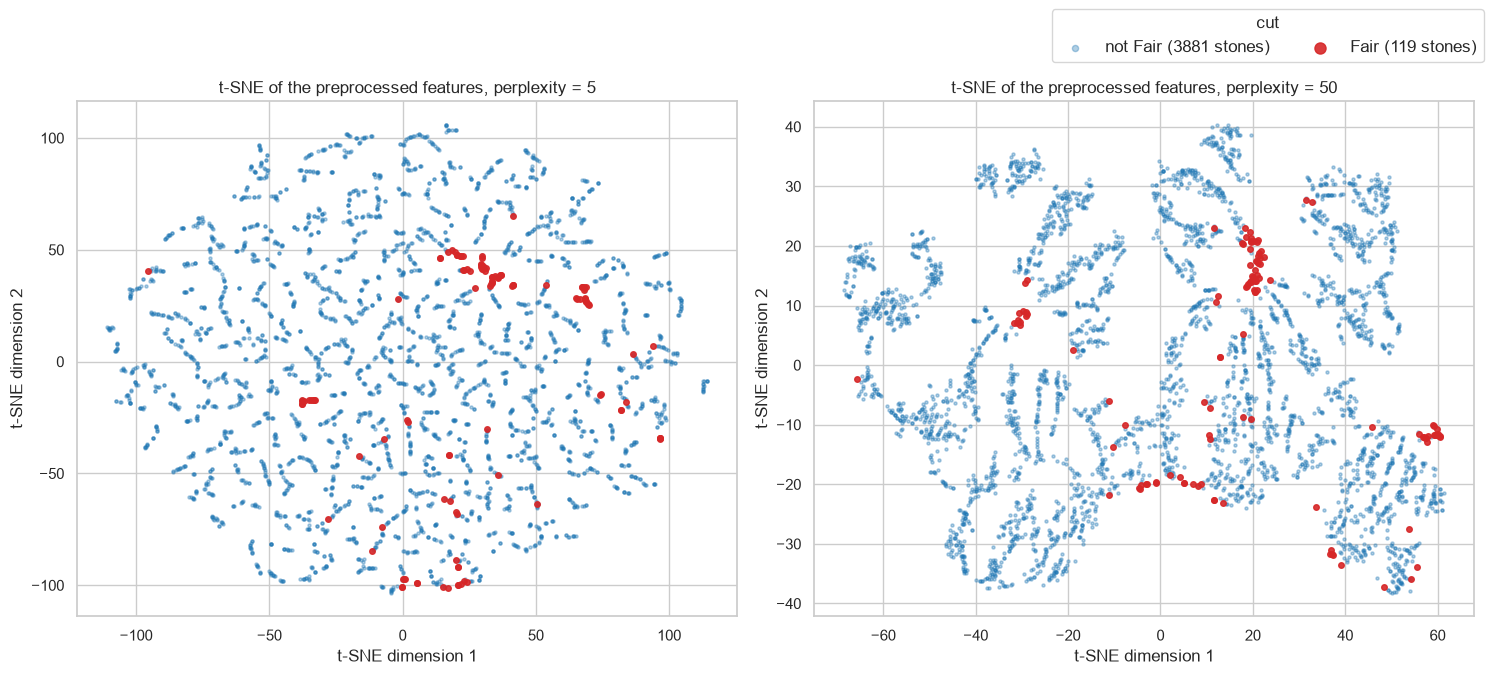

TSNE has a transform method: False


In [29]:
# Q10 d. A 2-D picture of the two classes with t-SNE
# A stratified sample of TRAINING stones only; t-SNE is slow on 43,000 rows.
X_sample, _, y_sample, _ = train_test_split(Xc_train, yc_train, train_size=4000,random_state=42, stratify=yc_train)
prep = SkPipeline([('features', FunctionTransformer(feature_engineer_numeric_only)),
                   ('impute', SimpleImputer(strategy='median')),
                   ('log', FunctionTransformer(np.log1p)),
                   ('scale', StandardScaler())])
Z = prep.fit_transform(X_sample)
print('sample: %d stones, %d of them Fair' % (len(y_sample), y_sample.sum()))

fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
for ax, perplexity in zip(axes, [5, 50]):
    embedding = TSNE(n_components=2, perplexity=perplexity,init='pca', random_state=42).fit_transform(Z)
    for cls, name, colour, size, alpha in [(0, 'not Fair', 'tab:blue', 5, 0.35),
                                           (1, 'Fair', 'tab:red', 16, 0.9)]:
        mask = (y_sample == cls).to_numpy()
        ax.scatter(embedding[mask, 0], embedding[mask, 1], s=size, alpha=alpha,
                   c=colour, label='%s (%d stones)' % (name, mask.sum()))
    ax.set_title('t-SNE of the preprocessed features, perplexity = %d' % perplexity, fontsize=12)
    ax.set_xlabel('t-SNE dimension 1')
    ax.set_ylabel('t-SNE dimension 2')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title='cut', loc='upper right', bbox_to_anchor=(1.0, 1.1), ncol=2)
fig.tight_layout()
plt.show()

# Can a fitted t-SNE map NEW stones? A pipeline step needs a transform method.
print('TSNE has a transform method:', hasattr(TSNE(), 'transform'))

**Your conclusions for Q10:**

b.
Stratified data makes sure that there is equal representation of data in both training and testing split.

c.
For a dataset like this which is heavily imbalanced, F1 and recall would be better measures. F1 tries to balance precision and recall. Recall also checks for how many fair diamonds are correctly classified.

d.

1. Class distribution: Fair stones (red) appear in several small clumps rather than one clearly separated region. They are also mixed among the not Fair stones (blue). This suggests that separating the classes is difficult.
2. Linear vs tree-based models: A simple linear classifier may struggle because the Fair class does not form one clearly separable region. A tree-based model may perform better because it can learn non-linear decision boundaries and combinations of feature thresholds. However, the plot alone cannot establish which model will perform better; test metrics must confirm this.
3. Effect of perplexity:

- Perplexity 5: Focuses more on local neighbourhoods, showing scattered small groups.
- Perplexity 50: Considers broader neighbourhoods, producing a more globally structured view. Fair stones still appear in multiple groups and overlap with not Fair stones.

4. What not to infer: Do not interpret distances between distant clusters, cluster sizes, or apparent gaps as exact measures of similarity or class separability. t-SNE is a 2-D projection and can distort the original high-dimensional distances and structure.
5. Why t-SNE is not in the prediction pipeline: It is used here for visual exploration, not prediction. It does not naturally provide a stable, straightforward transformation for unseen data using the standard workflow. It is also stochastic and mainly preserves local neighbourhoods. The classifier should instead use the original preprocessed features to learn and predict.


## Q11. A classification pipeline, with no special treatment

Build two pipelines with the same four preprocessing steps as in Q6
(`FunctionTransformer(feature_engineer_numeric_only)`,
`SimpleImputer(strategy='median')`, `FunctionTransformer(np.log1p)`,
`StandardScaler()`), ending in:

- `LogisticRegression(max_iter=1000)`
- `RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)`

Fit both on the stratified training set from Q10 and report all the metrics in
`classification_metrics` on the test set, average precision included (use
`predict_proba(...)[:, 1]` as the score). Draw the two confusion matrices.

a. Compare the logistic regression's accuracy with the do-nothing baseline from
Q10 c. Then look at its recall. What has happened?

b. How does the random forest do on the Fair class? Why can it separate the
classes so much better than a linear model can?


                     accuracy  balanced accuracy  precision  recall     F1  average precision (PR-AUC)
logistic regression     0.978              0.650      0.907   0.301  0.452                       0.632
random forest           0.994              0.941      0.922   0.885  0.903                       0.927
always "not Fair"       0.970              0.500      0.000   0.000  0.000                         NaN


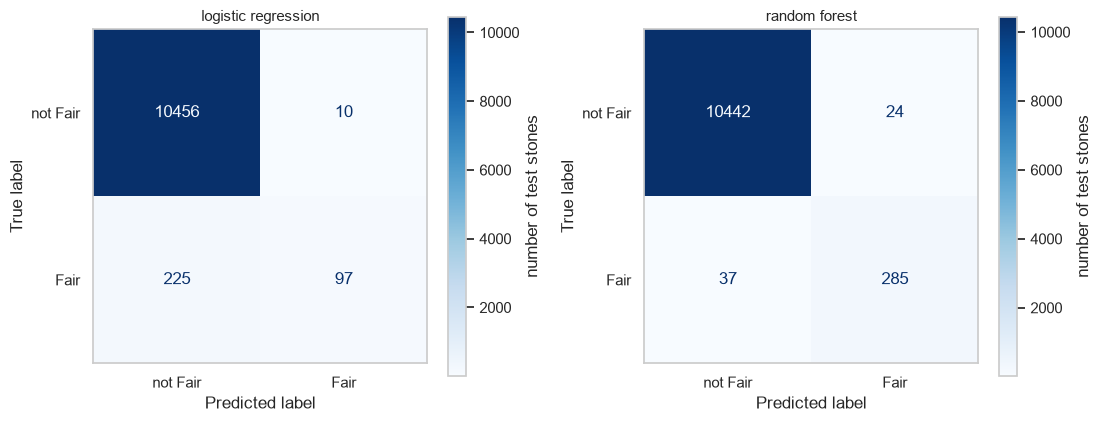

In [30]:
# Q11. Same preprocessing as Part A, now ending in a classifier
def preprocessing_steps():
    """The four preprocessing steps from Q6, as fresh objects."""
    return [('features', FunctionTransformer(feature_engineer_numeric_only)),
            ('impute', SimpleImputer(strategy='median')),
            ('log', FunctionTransformer(np.log1p)),
            ('scale', StandardScaler())]


plain_models = {
    'logistic regression': SkPipeline(preprocessing_steps()
                                      + [('model',  LogisticRegression(max_iter=1000))]),   
    'random forest': SkPipeline(preprocessing_steps()
                                + [('model', RandomForestClassifier(n_estimators=100,random_state=42, n_jobs=-1))]),       
}

rows = {}
for name, model in plain_models.items():
    model.fit(Xc_train, yc_train)
    rows[name] = classification_metrics(yc_test, model.predict(Xc_test),
                                        model.predict_proba(Xc_test)[:, 1])  
rows['always "not Fair"'] = classification_metrics(yc_test, always_not_fair)
print(pd.DataFrame(rows).T.round(3).to_string())

confusion_matrices(plain_models, Xc_test, yc_test)

**Your conclusions for Q11:**

a.
There is a slight improvement in accuracy but we know that we should be lookin at the other values as well. But it's recall and F1 are still on the lower end. Which overall doesnt make it a good model.

b.
Random forest combines multiple decision trees to capture non-linear patterns while a linear model has a linear separation boundary.


## Q12. Handling the imbalance inside the pipeline

Try three remedies from the lecture, each with both classifiers, keeping
everything else fixed:

1. **Class weights.** `class_weight='balanced'` on the model, so that mistakes on
   the rare class cost more during training.
2. **SMOTE.** Use an `imblearn` pipeline (`ImbPipeline`) with
   `SMOTE(random_state=42)` placed after the scaler and before the model.
3. **SMOTE followed by ENN.** As 2, with `EditedNearestNeighbours()` after SMOTE
   to clean up the points near the class boundary.

a. Put all eight results (the plain models from Q11 and the three remedies) in one
table. What did the remedies do to recall, precision and F1? Did they improve the
average precision? What does the answer tell you about what they actually change?
This table compares eight models on the test set, which is fine for reporting. If
you had to _choose_ one of them, how should you do it without using the test set?

b. A fourth remedy needs no retraining: keep the plain logistic regression and
lower the decision threshold. The threshold is a setting you choose, so it must be
chosen **without** the test set. Use `cross_val_predict` with 5 stratified folds on
the **training** set to get an out-of-fold probability for every training stone,
and compute precision, recall and F1 at the thresholds given. Which threshold
reaches roughly the recall of the class-weighted model, and how does its precision
compare? Then pick the threshold with the highest cross-validated F1 (the best
choice if a missed Fair stone and a false alarm cost the same), and only then
evaluate it on the test set, once. How close is the cross-validated F1 to the test
F1? Why would choosing the threshold by looking at test results be a mistake?


In [31]:
# Q12 a. Three remedies, both classifiers
def make_classifier(name, **kwargs):
    if name == 'logistic regression':
        return LogisticRegression(max_iter=1000, **kwargs)
    return RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1, **kwargs)


rows = []
for name in ['logistic regression', 'random forest']:
    variants = {
        'none': plain_models[name],
        'class weights': SkPipeline(preprocessing_steps()
                                    + [('model', make_classifier(name, class_weight='balanced'))]), 
        'SMOTE': ImbPipeline(preprocessing_steps()
                             + [('smote', SMOTE(random_state=42)),            
                                ('model', make_classifier(name))]),
        'SMOTE + ENN': ImbPipeline(preprocessing_steps()
                                   + [('smote', SMOTE(random_state=42)),
                                      ('enn', EditedNearestNeighbours()),         
                                      ('model', make_classifier(name))]),
    }
    for remedy, model in variants.items():
        if remedy != 'none':
            model.fit(Xc_train, yc_train)
        m = classification_metrics(yc_test, model.predict(Xc_test),
                                   model.predict_proba(Xc_test)[:, 1])
        rows.append({'model': name, 'remedy': remedy, **m})
remedies = pd.DataFrame(rows).set_index(['model', 'remedy']).round(3)
print(remedies.to_string())

                                   accuracy  balanced accuracy  precision  recall     F1  average precision (PR-AUC)
model               remedy                                                                                          
logistic regression none              0.978              0.650      0.907   0.301  0.452                       0.632
                    class weights     0.839              0.819      0.133   0.798  0.228                       0.496
                    SMOTE             0.838              0.811      0.131   0.783  0.224                       0.487
                    SMOTE + ENN       0.844              0.813      0.135   0.780  0.230                       0.490
random forest       none              0.994              0.941      0.922   0.885  0.903                       0.927
                    class weights     0.993              0.945      0.865   0.894  0.879                       0.930
                    SMOTE             0.991              0.956  

In [32]:
# Q12 b. Choose the threshold on the TRAINING data, then test it once
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_scores = cross_val_predict(plain_models['logistic regression'],Xc_train, yc_train, cv=cv, method='predict_proba')[:, 1]

rows = []
for threshold in [0.5, 0.3, 0.2, 0.1, 0.05, 0.03]:
    pred = (oof_scores >= threshold).astype(int)
    rows.append({'threshold': threshold,
                 'precision': precision_score(yc_train, pred, zero_division=0),
                 'recall': recall_score(yc_train, pred),
                 'F1': f1_score(yc_train, pred)})
print('out-of-fold results on the TRAINING set (5-fold CV):')
print(pd.DataFrame(rows).round(3).to_string(index=False))

# The threshold with the best cross-validated F1, on a finer grid.
grid = np.round(np.arange(0.02, 0.61, 0.01), 2)
cv_f1 = [f1_score(yc_train, (oof_scores >= t).astype(int)) for t in grid]
best_threshold = grid[int(np.argmax(cv_f1))]
print()
print('threshold chosen by CV: %.2f (cross-validated F1 %.3f)' % (best_threshold, max(cv_f1)))

# Only now look at the test set, once, with the chosen threshold.
test_scores = plain_models['logistic regression'].predict_proba(Xc_test)[:, 1]
final_pred = (test_scores >= best_threshold).astype(int)
print('test set at that threshold:')
print(pd.Series(classification_metrics(yc_test, final_pred)).round(3).to_string())

out-of-fold results on the TRAINING set (5-fold CV):
 threshold  precision  recall    F1
      0.50      0.880   0.273 0.416
      0.30      0.753   0.467 0.576
      0.20      0.613   0.594 0.604
      0.10      0.381   0.737 0.503
      0.05      0.211   0.807 0.334
      0.03      0.134   0.831 0.231

threshold chosen by CV: 0.22 (cross-validated F1 0.608)
test set at that threshold:
accuracy             0.980
balanced accuracy    0.786
precision            0.688
recall               0.581
F1                   0.630


**Your conclusions for Q12:**

a.
Logistic regression:
Recall -> increased (0.3 to 0.78)
Precision -> decreased (0.9 to 0.3)
F1 ->decreased (0.45 to 0.23)
Average Precision -> decreased (0.63 to 0.49)

Random forest:
Recall -> increased slightly (0.88 to 0.91)
Precision -> decreased (0.92 to 0.79)
F1 ->decreased (0.9 to 0.85)
Average Precision -> decreased (0.92 to 0.911 , for class weights it was similar)

The average precision did not improve.

The change increases recall, false positives while decreasing precision,f1. They help with improving the model for classifying the rare classes but not necessarily the entire model.

Based on the table i would select the random forest without anything else.

b.
The threshold 0.05 reaches roughly the recall of the class-weighted model, the precision is higher as well.
On picking a threshold of 0.22, the f1 score is almost the same for cross-validation and test set (0.022 difference).
Using the test results to set the threshold would cause data leakage issues.


## Q13. Where does SMOTE belong?

In Q12 SMOTE sat inside an `imblearn` pipeline. A common mistake is to resample the
whole dataset first and split afterwards. Do exactly that, as a demonstration only:
transform all the rows with the preprocessing steps, apply SMOTE to all of them,
then split the resampled data (stratified, `test_size=0.2`, `random_state=42`) and
fit the same random forest.

a. Compare its test precision, recall and F1 with the random forest + SMOTE result
from Q12. What has gone wrong? Explain where the synthetic points come from, and
why some of the "test" stones are no longer unseen.

b. The fitted `ImbPipeline` from Q12 applies SMOTE during `fit` but skips it during
`predict`. Explain why both halves of that rule are needed: what would go wrong if
SMOTE also ran at prediction time, and what would go wrong if the test set were
resampled before scoring?

c. Look again at the first line of the cell in a: the preprocessing is _also_
fitted on all the rows before the split. So that cell actually makes **two**
mistakes. Name both. To find out which one inflated the score, repeat the
demonstration with the preprocessing fitted on the training rows only (SMOTE still
before the split). Using this and your result from Q5, say which mistake is
responsible.


In [33]:
# Q13 a. The wrong way round: resample everything, then split (demonstration only)
all_transformed = SkPipeline(preprocessing_steps()).fit_transform(X_cls)
X_resampled, y_resampled =SMOTE(random_state=42).fit_resample(all_transformed, y_cls)
print('rows before SMOTE: %d, after: %d (Fair share %.0f%%)'
      % (len(y_cls), len(y_resampled), 100 * y_resampled.mean()))

Xl_train, Xl_test, yl_train, yl_test = train_test_split(
    X_resampled,
    y_resampled,
    test_size=0.2,
    random_state=42,
    stratify=y_resampled
)
leaky_forest = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
leaky_forest.fit(Xl_train, yl_train)

comparison = pd.DataFrame({
    'SMOTE before the split (leaky)': classification_metrics(yl_test, leaky_forest.predict(Xl_test)),
    'SMOTE inside the pipeline (Q12)': remedies.loc[('random forest', 'SMOTE')].drop(
        'average precision (PR-AUC)'),
}).T.round(3)
print(comparison.to_string())
# Note also: the leaky test set is half synthetic stones. What population is that
# score describing?

rows before SMOTE: 53940, after: 104660 (Fair share 50%)
                                 accuracy  balanced accuracy  precision  recall     F1
SMOTE before the split (leaky)      0.992              0.992      0.993   0.992  0.992
SMOTE inside the pipeline (Q12)     0.991              0.956      0.796   0.919  0.853


In [34]:
# Q13 c. Separate the two mistakes: preprocessing fitted on the TRAINING rows only,
# SMOTE still applied to every row before the split (demonstration only).
prep_train_only = SkPipeline(preprocessing_steps()).fit(Xc_train)
X_res2, y_res2 = SMOTE(random_state=42).fit_resample(prep_train_only.transform(X_cls), y_cls)
Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    X_res2, y_res2, test_size=0.2, random_state=42, stratify=y_res2)
forest_smote_leak_only = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
forest_smote_leak_only.fit(Xs_train, ys_train)
comparison.loc['SMOTE before the split, preprocessing fitted on train only'] = pd.Series(
    classification_metrics(ys_test, forest_smote_leak_only.predict(Xs_test))).round(3)
print(comparison.to_string())

                                                            accuracy  balanced accuracy  precision  recall     F1
SMOTE before the split (leaky)                                 0.992              0.992      0.993   0.992  0.992
SMOTE inside the pipeline (Q12)                                0.991              0.956      0.796   0.919  0.853
SMOTE before the split, preprocessing fitted on train only     0.992              0.992      0.993   0.992  0.992


**Your conclusions for Q13:**

a.
Since the test data is also used, there is data leakage and the values of accuracy, precision, recall and f1 are artificially high. The data has already been seen due to using of SMOTE technique.

b.
SMOTE generates synthetic minority-class samples to balance the training data and help the model learn.
If SMOTE ran during prediction time, it would have seen some of the observations. Resampling test data would change the evaluation and make the results invalid.

c.
The two mistakes are:

Data leakage from preprocessing: preprocessing was fitted on the entire dataset before splitting, allowing test-set information to influence the transformations.
Data leakage from SMOTE: synthetic samples were created before splitting, allowing synthetic training points to be influenced by future test observations.
SMOTE before the split was the main mistake responsible for inflating the score, while preprocessing leakage had little observable effect here.
